# Практическое задание № 2. Нейронные сети


**Работу выполнил (а):**

Басиони Абдельсалам Али Абдельсалам, 465144

## Прогнозирование цены на жилье с помощью нейросетевой регрессионной модели

Необходимо по имеющимся данным о ценах на жильё предсказать окончательную цену каждого дома с учетом характеристик домов с использованием нейронной сети. Описание набора данных  содержит 80 классов (набор переменых) классификации оценки типа жилья, и находится в файле `data_description.txt`.

В работе требуется дополнить раздел «Моделирование» в подразделе «Построение и обучение модели» создать и инициализировать последовательную модель нейронной сети с помощью фрэймворков тренировки нейронных сетей как: Torch или Tensorflow. Скомпилировать нейронную сеть выбрав функцию потерь и оптимизатор соответственно. Оценить точность полученных результатов. Вывести предсказанные данные о продаже.


### Импорт библиотек
Импортируем необходимые библиотеки:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

### Считываем набор данных


Загрузим набор данных и присвоим следующими переменные:

* `train_data`: данные, используемые для обучения модели
* `test_data`: данные, используемые для проверки модели

In [ ]:
train_data = pd.read_csv('/data/notebook_files/train.csv')
test_data = pd.read_csv('/data/notebook_files/test.csv')
#we have 2 files train and test

## Подготовка данных
### Отобразим обучающие и проверочные данные:

In [3]:
train_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
test_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


Как можно видеть, `train_data` имеет на один столбец больше, чем `test_data`, это столбец `SalePrice`, для обучения модели перед применением ее для предсказания меток в test_data.

### Проверяем нет ли тестовые данные пустых значений значений (Nan)

Построим функцию `def missing_value_checker` для проверки и подсчёта пропущеных значений в test_data. А также выведем тип данных этих значений.


In [ ]:
def missing_value_checker(data):
    list = []
    for feature, content in data.items():
        if data[feature].isnull().values.any():

            sum = data[feature].isna().sum()   #نحسب عدد القيم الناقصة.

            type = data[feature].dtype     #نعرف نوع البيانات: هل هي أرقام أم نصوص   

            print (f'{feature}: {sum}, type: {type}')

            list.append(feature)
    print(list)

    print(len(list))

missing_value_checker(test_data)

MSZoning: 4, type: str
LotFrontage: 227, type: float64
Alley: 1352, type: str
Utilities: 2, type: str
Exterior1st: 1, type: str
Exterior2nd: 1, type: str
MasVnrType: 894, type: str
MasVnrArea: 15, type: float64
BsmtQual: 44, type: str
BsmtCond: 45, type: str
BsmtExposure: 44, type: str
BsmtFinType1: 42, type: str
BsmtFinSF1: 1, type: float64
BsmtFinType2: 42, type: str
BsmtFinSF2: 1, type: float64
BsmtUnfSF: 1, type: float64
TotalBsmtSF: 1, type: float64
BsmtFullBath: 2, type: float64
BsmtHalfBath: 2, type: float64
KitchenQual: 1, type: str
Functional: 2, type: str
FireplaceQu: 730, type: str
GarageType: 76, type: str
GarageYrBlt: 78, type: float64
GarageFinish: 78, type: str
GarageCars: 1, type: float64
GarageArea: 1, type: float64
GarageQual: 78, type: str
GarageCond: 78, type: str
PoolQC: 1456, type: str
Fence: 1169, type: str
MiscFeature: 1408, type: str
SaleType: 1, type: str
['MSZoning', 'LotFrontage', 'Alley', 'Utilities', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea'

Проверяем какие признаки в таблице можно оставить, а какие удалить. Если пропущенных значений слишком много, то удалим признак. Если их небольшое количество, то заполним `mean` или `median` для чисел, новая категория `missing` для строковых объектов.

В соответствии с этим:

– удалим ['Alley', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature'];

– заполним числовое отсутствующее значение значением `median`;

– заполним строковое отсутствующее значение значением `missing`.

In [ ]:
test_edited = test_data.drop(['Alley','FireplaceQu','PoolQC', 'Fence', 'MiscFeature'], axis=1)
train_edited = train_data.drop(['Alley','FireplaceQu','PoolQC', 'Fence', 'MiscFeature'], axis=1)

def nan_filler(data):
    for label, content in data.items():
        if pd.api.types.is_numeric_dtype(content):
            data[label] = content.fillna(content.median())  #numerical = median less sensitive to the outliers
        else:
            data[label] = content.astype("category").cat.as_ordered()
            data[label] = pd.Categorical(content).codes+1   #categorical turn it into numbers 

nan_filler(test_edited)
nan_filler(train_edited)  #we apply it to both files 

### Перепроверим наши данные:

In [7]:
missing_value_checker(test_edited)

[]
0


In [8]:
missing_value_checker(train_edited)

[]
0


In [9]:
train_edited.shape, test_edited.shape

((1460, 76), (1459, 75))

In [ ]:
test_edited.info() #تعرض معلومات عن الجدول

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   int8   
 3   LotFrontage    1459 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   int8   
 6   LotShape       1459 non-null   int8   
 7   LandContour    1459 non-null   int8   
 8   Utilities      1459 non-null   int8   
 9   LotConfig      1459 non-null   int8   
 10  LandSlope      1459 non-null   int8   
 11  Neighborhood   1459 non-null   int8   
 12  Condition1     1459 non-null   int8   
 13  Condition2     1459 non-null   int8   
 14  BldgType       1459 non-null   int8   
 15  HouseStyle     1459 non-null   int8   
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuilt      1459

In [11]:
train_edited.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 76 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   int8   
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   int8   
 6   LotShape       1460 non-null   int8   
 7   LandContour    1460 non-null   int8   
 8   Utilities      1460 non-null   int8   
 9   LotConfig      1460 non-null   int8   
 10  LandSlope      1460 non-null   int8   
 11  Neighborhood   1460 non-null   int8   
 12  Condition1     1460 non-null   int8   
 13  Condition2     1460 non-null   int8   
 14  BldgType       1460 non-null   int8   
 15  HouseStyle     1460 non-null   int8   
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

### Разделим данные

Поскольку мы не знаем метку (Цена) тестовых данных, для оценки модели, чтобы получить лучшую модель перед прогнозированием тестовых данных, разделим данные в файле train.scv на обучающие и проверочные данные, соотношение составляет 20%.

In [ ]:
X = train_edited.drop(['SalePrice', 'Id'], axis=1)  # Id is just a row number, not a feature
y = train_edited['SalePrice']
#train and validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.2, random_state=40)  #test_size = 0.2  20% for validatio and 80% for training 
#X = Features (Признаки) and y = Target (Целевая переменная).

#40 controls randomness to make experiments reproducible. Running the model again with the same setup should produce approximately the same results.

In [13]:
X_train.shape, test_edited.shape

((1168, 74), (1459, 75))

### Нормализация данных

Нейросеть обучается методом градиентного спуска. Как показано в лекции («Необходимость нормализации»), если признаки имеют разный масштаб (площадь участка — десятки тысяч, количество комнат — от 1 до 10), то веса меняются с очень разной скоростью и градиентный спуск плохо сходится к минимуму. Поэтому приводим каждый признак к среднему 0 и стандартному отклонению 1 (`StandardScaler`). Scaler обучаем только на обучающей части.

Цену (`SalePrice`) масштабируем так же: цены — сотни тысяч долларов, и без масштабирования сеть обучается нестабильно. После предсказания переводим ответ обратно в доллары (`inverse_transform`).

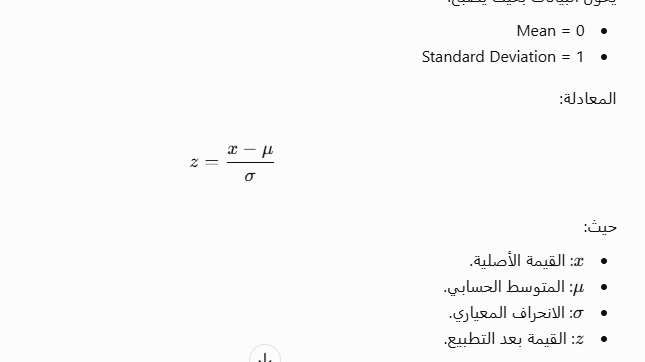

In [14]:
# Scale the features (fit only on the training part)
x_scaler = StandardScaler()
X_train_s = x_scaler.fit_transform(X_train)
X_val_s = x_scaler.transform(X_val)
X_test_s = x_scaler.transform(test_edited.drop('Id', axis=1))

# Scale the price the same way
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_val_s = y_scaler.transform(y_val.values.reshape(-1, 1))

### Baseline: линейная регрессия

Как советуют в лекции, сначала строю простую модель (baseline) — линейную регрессию. Нейросеть должна работать не хуже неё. Для оценки использую функцию `print_metrics` из лекции (MSE, RMSE, MAE, R²).

In [ ]:
def print_metrics(y_true, y_predicted):
    # regression metrics 
    print(f"Mean squared error: {mean_squared_error(y_true, y_predicted):.0f}")
    print(f"Root mean squared error: {np.sqrt(mean_squared_error(y_true, y_predicted)):.0f}")
    print(f"Mean absolute error: {mean_absolute_error(y_true, y_predicted):.0f}")
    print(f"R2 score: {r2_score(y_true, y_predicted):.3f}")

regressor = LinearRegression()  #create the model
regressor.fit(X_train_s, y_train)
lr_pred = regressor.predict(X_val_s)
print_metrics(y_val, lr_pred)  #lr_pred: Predicted house prices.
#A baseline is a simple reference model used to evaluate the performance of more advanced models.
#Linear Regression is a supervised machine learning algorithm that finds a linear relationship between input features and a target variable.
#MSE measures the average squared difference between actual and predicted values. Large prediction errors receive a much higher penalty because the errors are squared.
#RMSE is the square root of MSE.
#MAE calculates the average absolute difference between actual and predicted values.
#R² measures how much of the variance in house prices is explained by the model.

Mean squared error: 713765118
Root mean squared error: 26716
Mean absolute error: 18174
R2 score: 0.862


**Результат baseline:** линейная регрессия ошибается в среднем на 18 174 $ (R² = 0.862). Это нижняя граница качества: нейросеть должна дать ошибку меньше.

Our Neural Network should ideally achieve a lower MAE and a higher R² score.

## Моделирование

### Построение и обучение модели


Создайте последовательную модель нейронной сети с помощью фрэймворков тренировки нейронных сетей как: Torch или Tensorflow.

Activation Functions introduce nonlinearity into neural networks.

Without nonlinear activation functions, multiple layers of linear transformations are mathematically equivalent to a single linear transformation.

Adding nonlinear activation functions allows the network to learn complex nonlinear relationships.

In [ ]:
tf.keras.utils.set_random_seed(40)  # fixes all random seeds (Python, NumPy, TensorFlow) for reproducible results

model = keras.Sequential([
    keras.Input(shape=(X_train_s.shape[1],)),   # 74 input features
    layers.Dense(64, activation='relu'),        # input layer: 64 neurons
    layers.Dense(32, activation='relu'),        # hidden layer: 32 neurons
    layers.Dense(1)                             # output: the price (no activation, because this is regression)
])
model.summary()

#Input → Layer 1 → Layer 2 → Output
#A Dense layer is a fully connected layer.  Every neuron in the current layer receives information from all neurons in the previous layer.
#An Activation Fun is a mathematical function applied to a neuron's weighted sum of inputs plus bias. and It transforms the neuron's output before passing it to the next layer.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,913 (27.00 KB)

 Trainable params: 6,913 (27.00 KB)

 Non-trainable params: 0 (0.00 B)

**Архитектура:** вход (74 признака) → 64 нейрона → скрытый слой 32 нейрона → 1 выход.
* Веса и смещения — **обучаемые параметры** сети, они подбираются во время обучения.
* Функция активации **ReLU** = max(0, x). Она нелинейная (без неё несколько слоёв работали бы как одна линейная модель) и дифференцируемая (нужно для градиентного спуска).
* У выходного нейрона функции активации нет, потому что это **регрессия**: цена может быть любым числом.
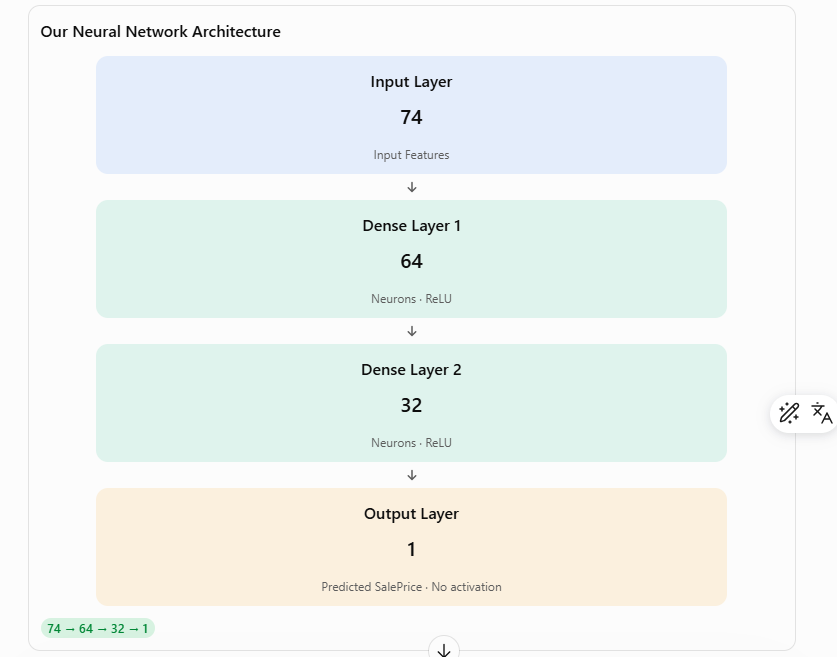

- Weights determine the strength and influence of each input connection.
- Bias is an additional trainable value that shifts the neuron's output.
- Both weights and biases are learned during training through optimization.

Скомпилируйте нейронную сеть, выбрав функцию потерь и оптимизатор соответственно.

In [ ]:
# Adam optimizer, MSE loss; MAE is printed as an extra metric
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
#An optimizer updates the model's weights and biases to minimize the loss function.


Обучите модель на обучающих данных `X_train` и `y_train` задав гиперпараметры вашей модели нейронной сети, например количество эпох (epochs), размер мини-выборки (batch_size) и другие.

In [ ]:
history = model.fit(X_train_s, y_train_s,
                    epochs=100,
                    batch_size=32,
                    validation_data=(X_val_s, y_val_s),
                    verbose=0)  # No training progress is displayed.
#An Epoch means one complete pass through the entire training dataset.
#The Batch Size is the number of training samples processed together before the model updates its weights and biases.
#Iteration	One batch-processing step

**Оцените полученные результаты**

Каждая эпоха состоит из обучения на `X_train` и проверки на валидационных данных (`validation_data`). Ниже — **кривые обучения**: ошибка на обучающей (`loss`) и валидационной (`val_loss`) выборках по эпохам.

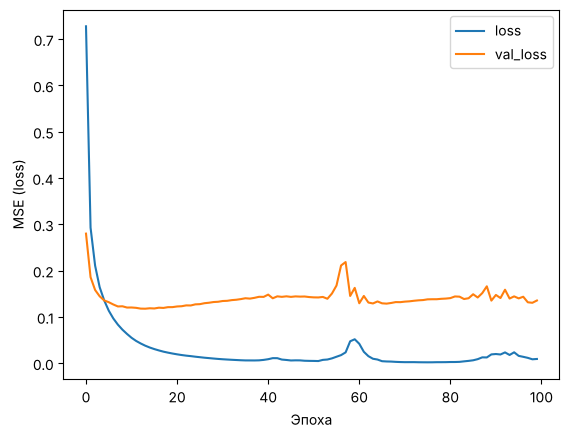

loss = 0.0092  val_loss = 0.1355


In [19]:
pd.DataFrame(history.history)[['loss', 'val_loss']].plot()
plt.ylabel('MSE (loss)')
plt.xlabel('Эпоха')
plt.show()
print('loss =', round(history.history['loss'][-1], 4), ' val_loss =', round(history.history['val_loss'][-1], 4))

**Кривые обучения:** ошибка на обучающей выборке быстро падает почти до нуля (0.009), а ошибка на валидации перестаёт уменьшаться уже после первых эпох и дальше немного растёт (0.136). Разница в 15 раз — это признак **переобучения**: сеть подстраивается под обучающие дома, но на новых данных лучше не становится.

In [20]:
scores = model.evaluate(X_val_s, y_val_s, verbose=0)
print('loss (MSE) =', round(scores[0], 4), ' MAE =', round(scores[1], 4), '(в масштабированных единицах)')

# Report in dollars: convert predictions back and print the metrics
val_pred = y_scaler.inverse_transform(model.predict(X_val_s, verbose=0)).ravel()
print_metrics(y_val, val_pred)

loss (MSE) = 0.1355  MAE = 0.2482 (в масштабированных единицах)


Mean squared error: 892986624
Root mean squared error: 29883
Mean absolute error: 20148
R2 score: 0.827


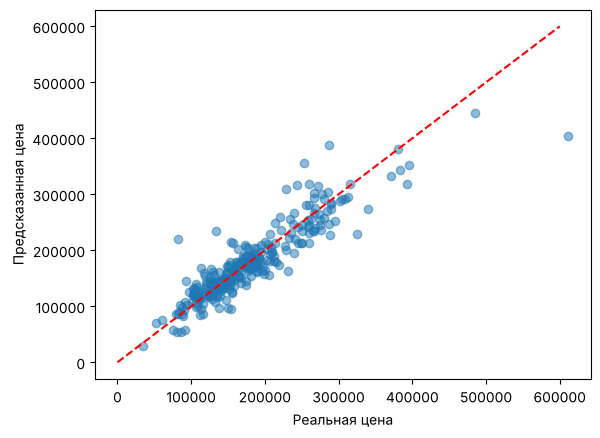

In [21]:
plt.scatter(y_val, val_pred, alpha=0.5)
plt.plot([0, 600000], [0, 600000], 'r--')   # red line = perfect prediction
plt.xlabel('Реальная цена')
plt.ylabel('Предсказанная цена')
plt.show()

**Вывод по базовой нейросети:** средняя ошибка 20 148 $, R² = 0.827 — это даже хуже, чем у линейной регрессии (18 174 $). Причины: переобучение (100 эпох) и функция потерь MSE, которая сильно реагирует на выбросы — несколько очень дорогих домов. Поэтому дальше подбираю гиперпараметры. На графике точки лежат около красной линии, больше всего ошибок на самых дорогих домах.

## Подбор гиперпараметров

Меняю по одному гиперпараметру, остальные оставляю как в базовой модели (64 нейрона, скрытый слой 32, Adam, MSE, 100 эпох, batch_size 32). Сравниваю по средней ошибке MAE в долларах на валидации (чем меньше, тем лучше).

In [22]:
def train_and_check(neurons=64, hidden=32, epochs=100, batch_size=32, optimizer='adam', loss='mse'):
    # build, train and evaluate one network; returns MAE in dollars and R2
    tf.keras.utils.set_random_seed(40)
    net = keras.Sequential()
    net.add(keras.Input(shape=(X_train_s.shape[1],)))
    net.add(layers.Dense(neurons, activation='relu'))
    if hidden > 0:
        net.add(layers.Dense(hidden, activation='relu'))
    net.add(layers.Dense(1))
    net.compile(optimizer=optimizer, loss=loss)
    net.fit(X_train_s, y_train_s, epochs=epochs, batch_size=batch_size, verbose=0)
    pred = y_scaler.inverse_transform(net.predict(X_val_s, verbose=0)).ravel()
    return round(mean_absolute_error(y_val, pred)), round(r2_score(y_val, pred), 3)

def show(results, title):
    # print a table and draw a bar chart for one experiment
    table = pd.DataFrame(results, columns=['Вариант', 'MAE, $', 'R2'])
    print(table.to_string(index=False))
    plt.bar(table['Вариант'].astype(str), table['MAE, $'])
    plt.title(title)
    plt.ylabel('MAE, $')
    plt.show()

### 1. Количество нейронов на входном слое

 Вариант  MAE, $    R2
      16   22476 0.773
      64   20148 0.827
     256   16969 0.864


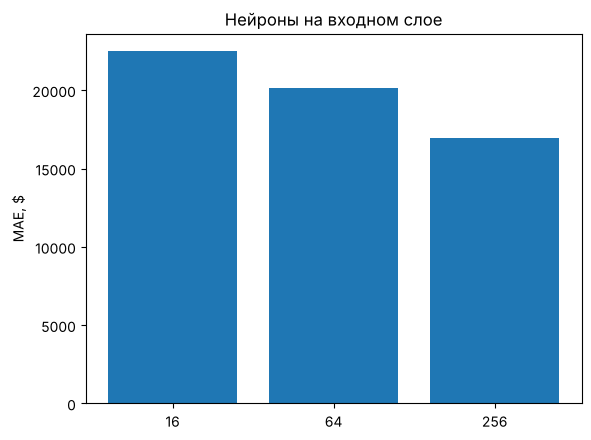

In [23]:
results = []
for n in [16, 64, 256]:
    mae, r2 = train_and_check(neurons=n)
    results.append([n, mae, r2])
show(results, 'Нейроны на входном слое')

**Результат:** чем больше нейронов на входном слое, тем меньше ошибка: 16 нейронов — 22 476 $, 64 — 20 148 $, 256 — 16 969 $. У маленькой сети меньше обучаемых параметров, и ей не хватает «ёмкости», чтобы описать зависимость цены от 74 признаков.

### 2. Скрытый слой с разным количеством нейронов

 Вариант  MAE, $    R2
       0   23719 0.768
      32   20148 0.827
     128   20606 0.828


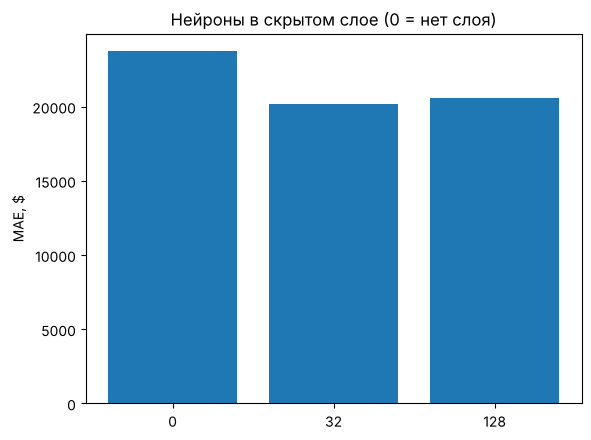

In [24]:
results = []
for h in [0, 32, 128]:      # 0 = no hidden layer
    mae, r2 = train_and_check(hidden=h)
    results.append([h, mae, r2])
show(results, 'Нейроны в скрытом слое (0 = нет слоя)')

**Результат:** без скрытого слоя ошибка самая большая (23 719 $, R² 0.77). Скрытый слой с ReLU заметно улучшает модель (около 20 000 $, R² 0.83), а увеличение скрытого слоя с 32 до 128 нейронов почти ничего не меняет. Это согласуется с теоремой об универсальной аппроксимации из лекции: сети с одним скрытым слоем и нелинейной функцией активации достаточно, чтобы приблизить сложную зависимость.

### 3. Количество эпох

 Вариант  MAE, $    R2
      10   19161 0.846
      50   20227 0.818
     100   20148 0.827
     200   20403 0.822


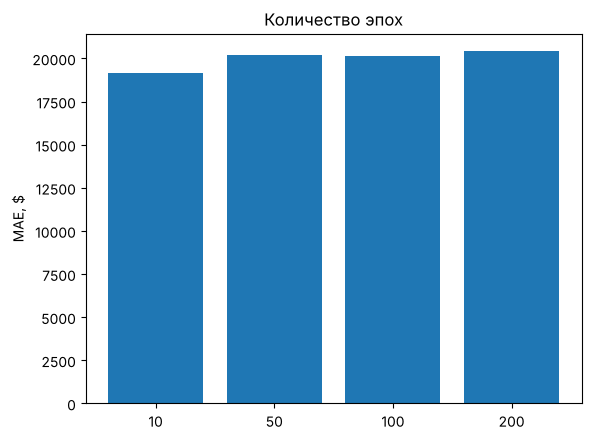

In [ ]:
results = []
for e in [10, 50, 100, 200]:
    mae, r2 = train_and_check(epochs=e)
    results.append([e, mae, r2])
show(results, 'Количество эпох')

##An Epoch means one complete pass through the entire training dataset.


**Результат:** хороший результат есть уже после 10 эпох (19 161 $). Дальше ошибка на валидации почти не уменьшается, а при 200 эпохах становится немного хуже. Как видно на кривых обучения, после нескольких эпох сеть начинает переобучаться: ошибка на обучении продолжает падать, а на валидации — нет.

### 4. Размер мини-выборки (batch_size)

 Вариант  MAE, $    R2
      16   19984 0.836
      32   20148 0.827
     128   20700 0.819


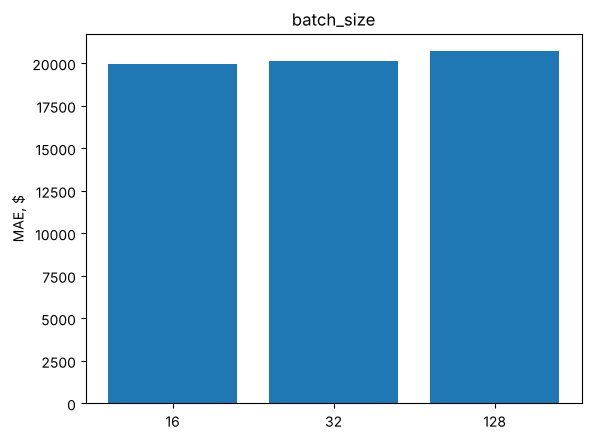

In [ ]:
results = []
for b in [16, 32, 128]:
    mae, r2 = train_and_check(batch_size=b)
    results.append([b, mae, r2])
show(results, 'batch_size')

##the weight is updated after every 16 samples
#The Batch Size is the number of training samples processed together before the model updates its weights and biases.

**Результат:** разница небольшая: batch_size 16 — 19 984 $, 32 — 20 148 $, 128 — 20 700 $. Это стохастический градиентный спуск по мини-выборкам: при маленьком batch_size за эпоху больше обновлений весов (1168 / 16 ≈ 73, а при 128 — всего 10), поэтому сеть успевает обучиться лучше, но обучение идёт медленнее. Большой batch считается быстрее и даёт более точное направление градиента.

### 5. Оптимизаторы и функции потерь

Вариант  MAE, $    R2
   adam   20148 0.827
    sgd   18823 0.828
rmsprop   20077 0.835


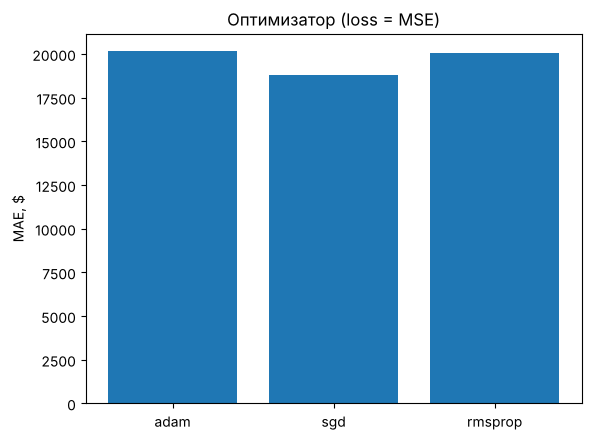

In [ ]:
results = []
for opt in ['adam', 'sgd', 'rmsprop']:
    mae, r2 = train_and_check(optimizer=opt)
    results.append([opt, mae, r2])
show(results, 'Оптимизатор (loss = MSE)')
#An optimizer is an algorithm that updates the network's weights and biases during training to minimize the loss function.
#SGD updates model parameters using gradient information. It is simple, but it may require careful learning-rate tuning and can converge more slowly.
#Adam combines momentum-like behavior with adaptive learning rates for individual parameters. It is often a good default optimizer.
#RMSprop adjusts parameter updates using a moving average of squared gradients, helping adapt the step size during training.

Вариант  MAE, $    R2
    mse   20148 0.827
    mae   17365 0.854
  huber   21651 0.819


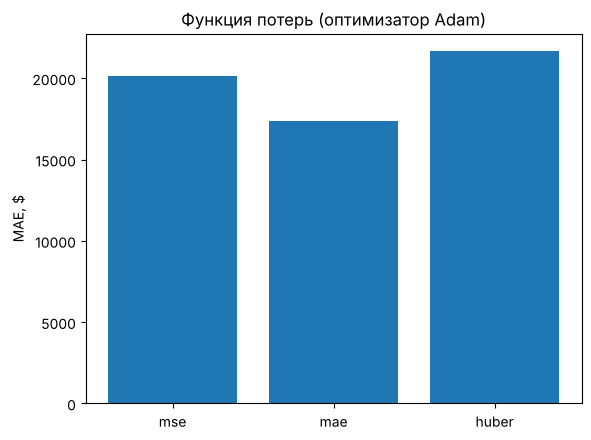

In [ ]:
results = []
for l in ['mse', 'mae', 'huber']:
    mae, r2 = train_and_check(loss=l)
    results.append([l, mae, r2])
show(results, 'Функция потерь (оптимизатор Adam)')
#A loss function measures the difference between the actual target values and the model's predictions.
#During training, the neural network tries to minimize this loss by updating its weights and biases.

**Результат:** оптимизаторы дали близкие результаты (Adam 20 148 $, SGD 18 823 $, RMSprop 20 077 $). Функция потерь повлияла сильнее:
* **MSE** — 20 148 $: ошибки возводятся в квадрат, поэтому выбросы (очень дорогие дома) сильно влияют на обучение;
* **MAE** — 17 365 $, лучший результат: все ошибки учитываются одинаково, MAE устойчивее к выбросам;
* **Huber** — 21 651 $: ведёт себя как MSE для маленьких ошибок и как MAE для больших. Порог δ = 1 здесь равен одному стандартному отклонению цены (≈ 80 тыс. $), поэтому для большинства домов Huber работает как MSE.

**Итоговая модель:** 256 нейронов, скрытый слой 32, 50 эпох, batch_size 16, Adam, loss MAE.

### Итоговая модель

Собираю лучшие значения из экспериментов.

In [29]:
final_mae, final_r2 = train_and_check(neurons=256, hidden=32, epochs=50,
                                      batch_size=16, optimizer='adam', loss='mae')
print('Итоговая модель: MAE =', final_mae, '$,  R2 =', final_r2)

Итоговая модель: MAE = 14820 $,  R2 = 0.894


            Модель  MAE, $    R2
Линейная регрессия   18174 0.862
 Базовая нейросеть   20148 0.827
Итоговая нейросеть   14820 0.894


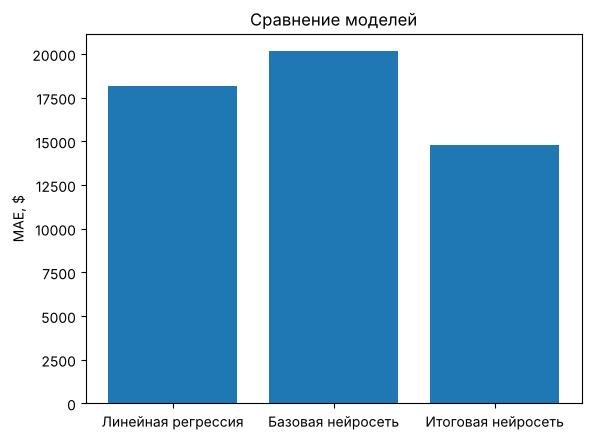

In [30]:
# Compare: linear regression (baseline), first network, final network
comparison = pd.DataFrame({
    'Модель': ['Линейная регрессия', 'Базовая нейросеть', 'Итоговая нейросеть'],
    'MAE, $': [round(mean_absolute_error(y_val, lr_pred)), round(mean_absolute_error(y_val, val_pred)), final_mae],
    'R2': [round(r2_score(y_val, lr_pred), 3), round(r2_score(y_val, val_pred), 3), final_r2],
})
print(comparison.to_string(index=False))
plt.bar(comparison['Модель'], comparison['MAE, $'])
plt.ylabel('MAE, $')
plt.title('Сравнение моделей')
plt.show()

### Прогнозирование

In [ ]:
# Train the final network and predict prices for the test houses
tf.keras.utils.set_random_seed(40)
final_model = keras.Sequential([
    keras.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
final_model.compile(optimizer='adam', loss='mae')
final_model.fit(X_train_s, y_train_s, epochs=50, batch_size=16, verbose=0)

preds = y_scaler.inverse_transform(final_model.predict(X_test_s, verbose=0))  # back to dollars
preds
#We used two hidden layers with 256 and 32 neurons, respectively. We used ReLU as the activation function, Adam as the optimizer, and MAE as the loss function.
#  We trained the model for 50 epochs with a batch size of 16. We selected these hyperparameters based on experiments and validation performance.

In [32]:
output = pd.DataFrame(
{
    'Id':test_data['Id'],
    'SalePrice': np.squeeze(preds)
})
output

,Id,SalePrice
0,1461,122013.250000
1,1462,156577.328125
2,1463,168114.687500
3,1464,170328.234375
4,1465,163299.375000
...,...,...
1454,2915,86807.093750
1455,2916,88062.937500
1456,2917,163272.453125
1457,2918,122191.539062


## Задание


В задние представлено логика выполнения с использование tensorflow/keras. Выполнять можно как с использованием tensorflow/keras, так и pytorch.


**При выполнении:**

Выведите отчет нейросетевой регрессионной модели, для  прогнозирование цены на жилье.


Подберите  разные комбинации гиперпараметров таким образом, чтобы получить лучший результат на тестовом наборе данных.

Попробуйте использовать разное количество нейронов на входном слое. Опишите достигнутый результат.

Добавьте в нейронную сеть скрытый слой с разным количеством нейронов.

Используйте разное количество эпох. Опишите достигнутый результат.

Используйте разные размеры мини-выборки (batch_size). Опишите достигнутый результат.

Попробуйте использовать разные значения оптимизатора `optimizers` и функции потерь `loss`. Сравните полученные результаты.

**Вопросы:**

Как выше перечисленные параметры влияют на полученный вами результат?

Что такое эпоха (Epoch)? В чем отличие от итерации (Iteration)?

Что такое функция активации? Какие вам известны? Как и зачем используются в нейронной сети?

Что такое MSE(Mean Squared Error) - Средняя квадратичная ошибка? Что такое MAE(Mean Absolute Error)? Для чего используются.

## Ответы

**Отчёт.**
* Линейная регрессия (baseline): средняя ошибка 18 174 $, R² = 0.862.
* Базовая нейросеть (64 → 32 → 1, Adam, MSE, 100 эпох, batch_size 32): 20 148 $, R² = 0.827 — хуже baseline из-за переобучения.
* Итоговая нейросеть (256 → 32 → 1, Adam, MAE, 50 эпох, batch_size 16): **14 820 $, R² = 0.894** — лучше линейной регрессии на 18%, модель объясняет около 89% разброса цен.
![Screenshot 2026-11-09 224519.png](<attachment:Screenshot 2026-11-09 224519.png>)

**Как параметры влияют на результат?**
* Количество нейронов и скрытый слой определяют сложность модели (число обучаемых параметров). Слишком простая модель недообучается, слишком сложная — легче переобучается.
* Количество эпох: мало — сеть недообучена (кривые обучения не вышли на плато), много — переобучение (ошибка на валидации перестаёт падать или растёт). Здесь хватило 10–50 эпох.
* batch_size: маленький — больше обновлений весов за эпоху, обучение точнее, но медленнее; большой — быстрее.
* Оптимизатор определяет, как обновляются веса при градиентном спуске. Здесь Adam, SGD и RMSprop дали похожий результат.
* Функция потерь: MAE оказалась лучше MSE и Huber, потому что в данных есть выбросы — очень дорогие дома.

**Что такое эпоха? Чем отличается от итерации?**
Эпоха — один полный проход по всем обучающим данным; в каждой эпохе есть обучение (обновление весов) и проверка на валидации. Итерация — одно обновление весов по одной мини-выборке (batch). Итераций за эпоху = размер выборки / batch_size. Например, 1168 домов и batch_size 32 → 37 итераций за эпоху.

**Что такое функция активации? Какие известны? Зачем используются?**
Функция активации применяется к взвешенной сумме входов нейрона (плюс смещение). Требования из лекции:
1. **нелинейность** — без неё нейросеть работает как линейная модель, сколько бы слоёв ни было;
2. **дифференцируемость** — нужна для градиентного спуска (поэтому старая пороговая функция не подходит).

Примеры:
* **Sigmoid** (логистическая) — выход от 0 до 1, для бинарной классификации; минус — затухание градиента;
* **Tanh** — выход от −1 до 1, симметрична относительно нуля;
* **ReLU** = max(0, x) — самая популярная в скрытых слоях, используется в этой работе;
* **Leaky ReLU** — как ReLU, но с небольшим наклоном при x < 0, решает проблему «умерших» нейронов;
* **GELU** — используется в современных сетях (трансформеры);
* **Softmax** — на выходе многоклассовой классификации (вероятности классов).

В выходном слое регрессии функции активации нет: цена может быть любым числом.

**Что такое MSE и MAE? Для чего используются?**
* **MSE** (средняя квадратичная ошибка) = (1/N) · Σ (yᵢ − ŷᵢ)². Сильно штрафует большие ошибки, но чувствительна к выбросам. Единицы — квадрат единиц цели, поэтому для отчёта берут корень — **RMSE** (в долларах).
* **MAE** (средняя абсолютная ошибка) = (1/N) · Σ |yᵢ − ŷᵢ|. Все ошибки учитываются одинаково, устойчива к выбросам; показывает, на сколько долларов в среднем ошибается модель.

Обе используются в задачах регрессии: как **функция потерь** (её минимизирует сеть при обучении) и как **метрика** качества.

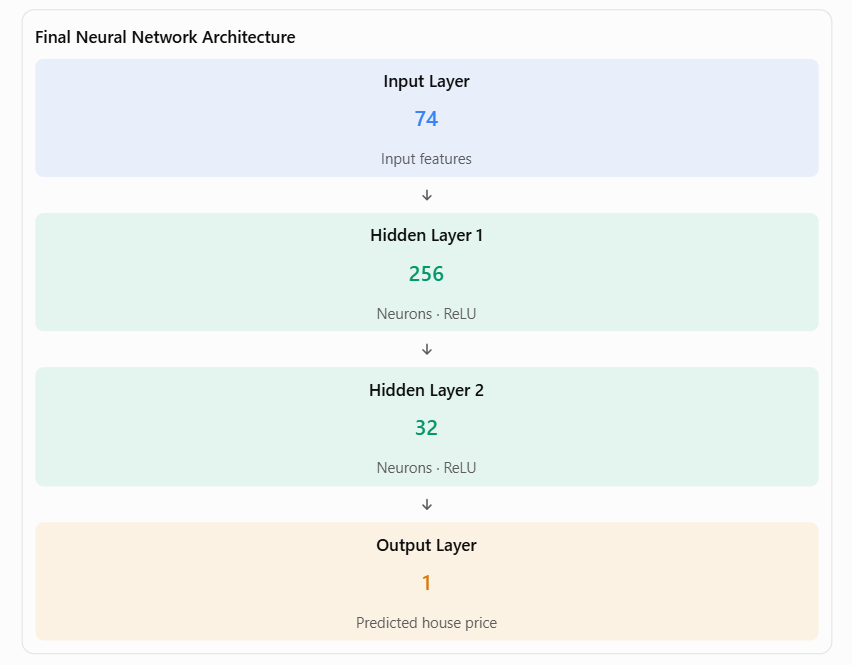